In [1]:
import myhda_ur as hda

In [2]:
hdata = hda.load_scifate()

In [3]:
top_hvg = hdata.get_highly_variable_genes(n=2000)

In [4]:
# Initialize a temporary subset object for the selected cells 

subset_traj_ = hdata[top_hvg, :]    # 2000 genes x allcells

In [6]:
# Get top HDTs
# Make sure to keep all cells available when using get_highly_dynamic_trajectories

top_traj = subset_traj_.get_highly_dynamic_trajectories(n=300)

# Trajectory

## Total RNA

### Concatenate first -> PCA

Trajectory × (gene × position) matrix    

↓ PCA 

Trajectory × PC matrix            

↓ similarity + spectral clustering

Clusters

In [6]:
# PCA on trajectory × (gene*timepoints) matrix

hdata.compute_PCA(
    data=subset_traj_,
    key="X",
    kind="trajectory",
    n_pc=20,
    trajectory_id=top_traj
)

PCA matrix trajectory x 20 PCs stored in HDAData.layers["pca_trajectory"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'pca_trajectory']
  similarities: []
  clusters: []
  embeddings: []
  trajectories: Yes

In [7]:
hdata.compute_similarity(
    data=subset_traj_,
    key="pca_trajectory",
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation"
)

Similarity "correlation_pca_trajectory_trajectory" stored!


HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'pca_trajectory']
  similarities: ['correlation_pca_trajectory_trajectory']
  clusters: []
  embeddings: []
  trajectories: Yes

In [8]:
sim_traj = hdata.similarities["correlation_pca_trajectory_trajectory"]

In [9]:
# Cluster using Graph-based Clustering - Spectral

hdata.cluster_spectral(
        sim = sim_traj,                                               
        kind = "trajectory",
        k = 6
    )

Cluster "spectral_k6_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'pca_trajectory']
  similarities: ['correlation_pca_trajectory_trajectory']
  clusters: ['spectral_k6_trajectory']
  embeddings: []
  trajectories: Yes

In [10]:
c1_spec_traj = hdata.clusters["spectral_k6_trajectory"]

In [11]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_traj_,
    key="pca_trajectory",
    kind="trajectory",
    trajectory_id=top_traj,
    id = "exp_dist"
)

UMAP embedding "umap_trajectory_exp_dist" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'pca_trajectory']
  similarities: ['correlation_pca_trajectory_trajectory']
  clusters: ['spectral_k6_trajectory']
  embeddings: ['umap_trajectory_exp_dist']
  trajectories: Yes

In [12]:
em_traj_ = hdata.embeddings["umap_trajectory_exp_dist"]

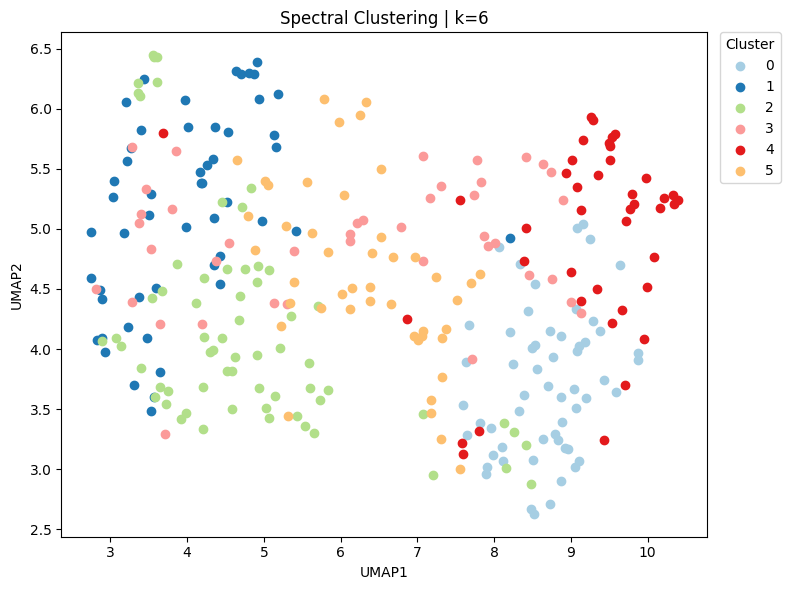

In [13]:
# Visualize 
hda.visualize.scatter(
    cluster=c1_spec_traj,
    embedding=em_traj_,
    title="Spectral Clustering | k=6",
    show_label=False
)

### PCA first -> Concatenate

Cell × gene matrix         

↓ PCA on cells

Cell × PC matrix      

↓ build trajectory vectors using PC scores

Trajectory × PC*timepoints matrix    

↓ similarity + spectral clustering

Clusters

In [14]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_traj_,
    key="X",
    kind="cell",
    n_pc=20
)

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'pca_trajectory', 'pca_cell']
  similarities: ['correlation_pca_trajectory_trajectory']
  clusters: ['spectral_k6_trajectory']
  embeddings: ['umap_trajectory_exp_dist']
  trajectories: Yes

In [15]:
# Compute traj-traj distance matrix in PC space
hdata.compute_similarity(
    data=subset_traj_,
    key="pca_cell",
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation"
)

Similarity "correlation_pca_cell_trajectory" stored!


HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'pca_trajectory', 'pca_cell']
  similarities: ['correlation_pca_trajectory_trajectory', 'correlation_pca_cell_trajectory']
  clusters: ['spectral_k6_trajectory']
  embeddings: ['umap_trajectory_exp_dist']
  trajectories: Yes

In [16]:
sim_pca_traj = hdata.similarities["correlation_pca_cell_trajectory"]

In [17]:
# Cluster in PC space
hdata.cluster_spectral(
    sim=sim_pca_traj,
    kind="trajectory",
    k=6
)

Cluster "spectral_k6_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'pca_trajectory', 'pca_cell']
  similarities: ['correlation_pca_trajectory_trajectory', 'correlation_pca_cell_trajectory']
  clusters: ['spectral_k6_trajectory']
  embeddings: ['umap_trajectory_exp_dist']
  trajectories: Yes

In [18]:
cl_pca_traj_ = hdata.clusters["spectral_k6_trajectory"]

In [19]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_traj_,
    key="pca_cell",
    kind="trajectory",
    trajectory_id=top_traj,
    id = "pca_based"
)

UMAP embedding "umap_trajectory_pca_based" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'pca_trajectory', 'pca_cell']
  similarities: ['correlation_pca_trajectory_trajectory', 'correlation_pca_cell_trajectory']
  clusters: ['spectral_k6_trajectory']
  embeddings: ['umap_trajectory_exp_dist', 'umap_trajectory_pca_based']
  trajectories: Yes

In [20]:
em_pca_traj_ = hdata.embeddings["umap_trajectory_pca_based"]

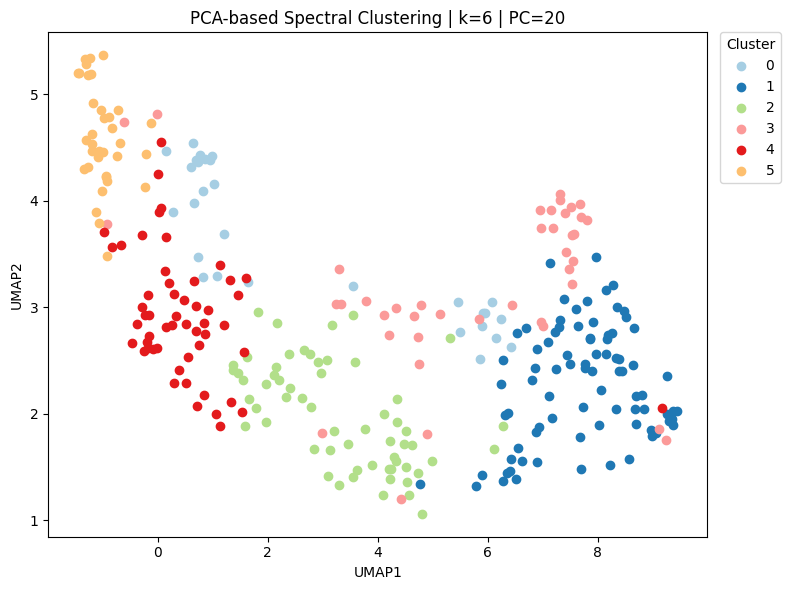

In [21]:
# Visualize 
hda.visualize.scatter(
    cluster=cl_pca_traj_,
    embedding=em_pca_traj_,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

## New RNA

### Concatenate first -> PCA

PCA matrix trajectory x 20 PCs stored in HDAData.layers["pca_trajectory"] 

Similarity "correlation_pca_trajectory_trajectory" stored!
Cluster "spectral_k6_trajectory" stored! 

UMAP embedding "umap_trajectory_exp_dist" stored! 



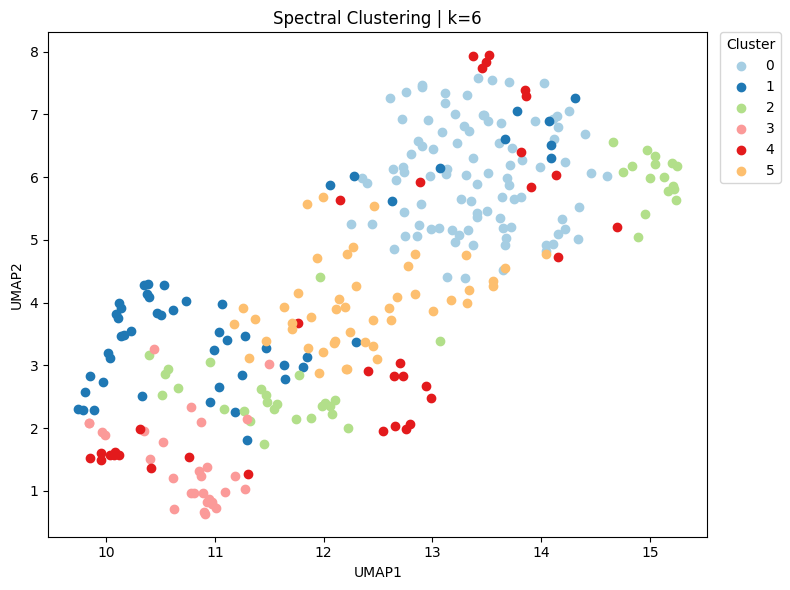

In [7]:
hdata.compute_PCA(
    data=subset_traj_,
    key="new_rna",
    kind="trajectory",
    n_pc=20,
    trajectory_id=top_traj
)

hdata.compute_similarity(
    data=subset_traj_,
    key="pca_trajectory",
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation"
)

sim3 = hdata.similarities["correlation_pca_trajectory_trajectory"]

hdata.cluster_spectral(
        sim = sim3,                                               
        kind = "trajectory",
        k = 6
    )

c13 = hdata.clusters["spectral_k6_trajectory"]

hdata.reduce_UMAP(
    data=subset_traj_,
    key="pca_trajectory",
    kind="trajectory",
    trajectory_id=top_traj,
    id = "exp_dist"
)

em3 = hdata.embeddings["umap_trajectory_exp_dist"]

hda.visualize.scatter(
    cluster=c13,
    embedding=em3,
    title="Spectral Clustering | k=6",
    show_label=False
)

### PCA first -> Concatenate

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 

Similarity "correlation_pca_cell_trajectory" stored!
Cluster "spectral_k6_trajectory" stored! 

UMAP embedding "umap_trajectory_pca_based" stored! 



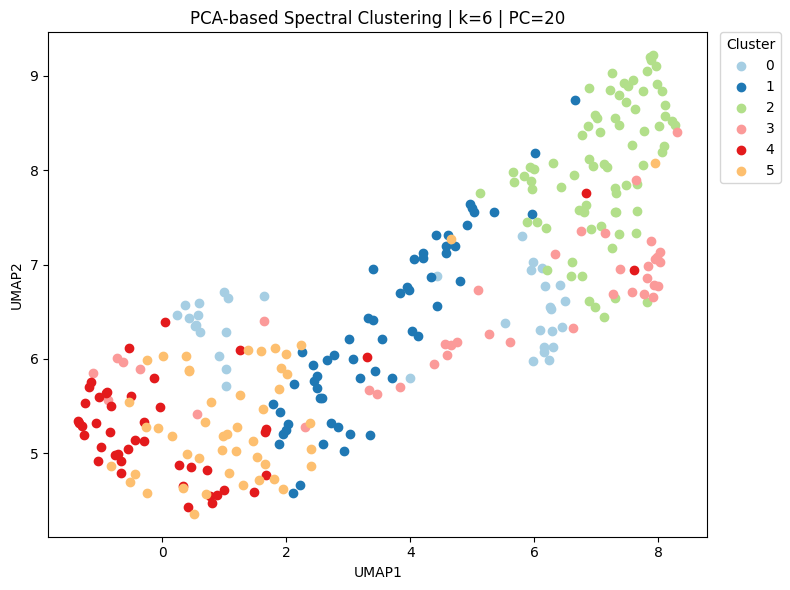

In [8]:
hdata.compute_PCA(
    data=subset_traj_,
    key="new_rna",
    kind="cell",
    n_pc=20
)

hdata.compute_similarity(
    data=subset_traj_,
    key="pca_cell",
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation"
)

sim4 = hdata.similarities["correlation_pca_cell_trajectory"]

hdata.cluster_spectral(
    sim=sim4,
    kind="trajectory",
    k=6
)

cl4 = hdata.clusters["spectral_k6_trajectory"]

hdata.reduce_UMAP(
    data=subset_traj_,
    key="pca_cell",
    kind="trajectory",
    trajectory_id=top_traj,
    id = "pca_based"
)

em4 = hdata.embeddings["umap_trajectory_pca_based"]

hda.visualize.scatter(
    cluster=cl4,
    embedding=em4,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

## Results comparison

![img7](temp/img7.jpg)